# Landau-Lifshitz-Gilbert Dynamics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/04-magnetization/01-LLG.ipynb)

Here, the magnetization simulations of the **udkm1Dsim** package are introduced with the Landau-Lifshitz-Gilbert (LLG) equation, the most basic of the magnetization models.
As an example, the laser-induced magnetization precession of a buried Ni layer in Pt-Cu-Ni heterostructures of {cite:t}`jarecki2024` is reproduced.
Their precession is driven by the demagnetization of the Ni and by its strain, which consists of a quasi-static expansion and of strain pulses, whose round trip through the heterostructure can be resonant with the precession.
An insulating MgO interlayer, which stops the heat transport via electrons, controls these driving mechanisms.

:::{admonition} Reference {cite}`jarecki2024`
:class: seealso
J. Jarecki, M. Mattern, F.-C. Weber, J.-E. Pudell, X.-G. Wang, J.-C. Rojas Sánchez, M. Hehn, A. von Reppert, and M. Bargheer,
*Controlling effective field contributions to laser-induced magnetization precession by heterostructure design*,
[Commun. Phys. 7, 112 (2024)](https://doi.org/10.1038/s42005-024-01602-z)
:::

The {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` class solves the LLG in its Landau-Lifshitz form for the unit vector $\mathbf{n}$ of the magnetization of every layer

\begin{align*}
\frac{d\mathbf{n}}{dt} = \frac{\gamma}{1+\alpha^2}\left(\mathbf{n} \times \mathbf{B}
+ \alpha \mathbf{n} \times (\mathbf{n} \times \mathbf{B})\right)
\end{align*}

with the Gilbert damping $\alpha$ {cite:p}`gilbert2004`, the gyromagnetic ratio $\gamma$, which defaults to the one of a free electron $\gamma_e = -1.761\times10^{11}$ rad/(s T), and the effective field $\mathbf{B}$.
The effective field is the sum of

* the external field $\mathbf{B}_\mathrm{ext}$,
* the anisotropy field $\mathbf{B}_\mathrm{A}$,
* the exchange field $\mathbf{B}_\mathrm{ex}$ between neighbouring layers, and
* the magnetoelastic field $\mathbf{B}_\mathrm{me}$ of the strain.

The definitions of these terms are described in the {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` class API documentation.
The amplitude $m$ of the magnetization $\mathbf{m} = m \mathbf{n}$ is not a dynamic variable of the LLG but an input.
The [inertial LLG](#example_iLLG) adds the inertia of the magnetization and the [LLB](#example_LLB) also describes the dynamics of the amplitude.

This example is adapted from the examples of [friweber/udkm1Dsim_LLG-LLB](https://github.com/friweber/udkm1Dsim_LLG-LLB) by [@friweber](https://github.com/friweber).

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

from udkm1Dsim.simulations.solvers import mean_field

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The three heterostructures of {cite:t}`jarecki2024` consist of a Pt cap layer, which absorbs most of the pump pulse, a Cu layer, which transports the energy via hot electrons, and a buried 22 nm thick Ni layer on a Ta seed layer and a glass substrate.
They only differ by the position of a 5 nm thick insulating MgO interlayer:

* sample 1: Pt 7 nm / Cu 95 nm / Ni 22 nm / Ta 8 nm / glass
* sample 2: Pt 7 nm / Cu 95 nm / MgO 5 nm / Ni 22 nm / Ta 8 nm / glass
* sample 3: Pt 10 nm / MgO 5 nm / Cu 92 nm / Ni 22 nm / Ta 8 nm / glass

The thermo-elastic parameters are taken from Table 1 of the paper.
The two-temperature model of the metals has the electronic heat capacity $C_e = \gamma_S T_e$ with the Sommerfeld constant $\gamma_S$ and the electronic heat conductivity $\kappa_e = \kappa_e^0 T_e / T_p$.
As **udkm1Dsim** takes the heat capacities per mass, they are divided by the density.
The paper relates the energy density of the electrons and phonons to the stress via the Grüneisen parameters $\Gamma$, which corresponds to the linear thermal expansion coefficients $\alpha = \Gamma C / C_{33}$ of the sub-systems with their heat capacity $C$ per volume and the elastic constant $C_{33} = \rho v_s^2$.
The insulators MgO and glass have no electronic heat conductivity, so the electrons cannot cross them.
The Ni is discretized into 2 nm thick layers, because the exchange coupling between thinner layers makes the LLG stiff and slows down the simulations considerably.

In [2]:
# Pt cap layer, which absorbs most of the pump pulse
rho = 21450 * u.kg / u.m**3  # density
v_s = 4.2 * u.nm / u.ps  # sound velocity
gamma_S = 730 * u.J / (u.m**3 * u.K**2)  # Sommerfeld constant
C_ph = 2.85e6 * u.J / (u.m**3 * u.K)  # heat capacity of the phonons
kappa_el_0 = 66 * u.W / (u.m * u.K)  # electronic heat conductivity at T_e = T_p
kappa_ph = 5.0 * u.W / (u.m * u.K)  # heat conductivity of the phonons
g = 3.75e17 * u.W / (u.m**3 * u.K)  # electron-phonon coupling
Gamma_el, Gamma_ph = 1.2, 2.6  # Grüneisen parameters
C_33 = rho * v_s**2  # elastic constant

layer_Pt = ud.Layer(
    "Pt",
    "Platinum",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    # two-temperature model
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{(gamma_S / rho).m_as('J/(kg*K**2)'):g}*T", C_ph / rho],
        therm_cond=[f"{kappa_el_0.m_as('W/(m*K)'):g}*T_0/T_1", kappa_ph],
        sub_system_coupling=[
            f"-{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[
            f"{(Gamma_el * gamma_S / C_33).m_as('1/K**2'):g}*T",
            Gamma_ph * C_ph / C_33,
        ],
        sub_system_labels=["e", "p"],  # electrons and phonons
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(0.576 + 8.078j)),
)
layer_Pt.thermal

Thermal Parameters
╔═════════════════════╦══════════╦══════════════════════════════╦════════╗
║ Parameter           ║  Symbol  ║                        Value ║ Unit   ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ therm_cond          ║    κₑ    ║                     66·Tₑ/Tₚ ║ W/K/m  ║
║                     ║    κₚ    ║                            5 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ heat_capacity       ║    cₑ    ║                   0.03403·Tₑ ║ J/K/kg ║
║                     ║    cₚ    ║                        132.9 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ lin_therm_exp       ║    αₑ    ║                2.315×10⁻⁹·Tₑ ║        ║
║                     ║    αₚ    ║                   1.958×10⁻⁵ ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ sub_system_coupling ║    Gₑ    ║ −3.75×10¹⁷·Tₑ + 3.75×10¹⁷·Tₚ ║ W/m³   ║
║                     ║    Gₚ    ║  3.75×10¹⁷·Tₑ − 3.75×10¹⁷·Tₚ ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ deb_wal_fac         ║  ⟨u²⟩ₑ   ║                            0 ║ m²     ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ num_sub_systems     ║    N     ║                            2 ║        ║
╚═════════════════════╩══════════╩══════════════════════════════╩════════╝

In [3]:
# Cu layer
rho = 8960 * u.kg / u.m**3
v_s = 5.2 * u.nm / u.ps
gamma_S = 100 * u.J / (u.m**3 * u.K**2)
C_ph = 3.44e6 * u.J / (u.m**3 * u.K)
kappa_el_0 = 396 * u.W / (u.m * u.K)
kappa_ph = 5.0 * u.W / (u.m * u.K)
g = 0.95e17 * u.W / (u.m**3 * u.K)
Gamma_el, Gamma_ph = 0.9, 2.0
C_33 = rho * v_s**2

layer_Cu = ud.Layer(
    "Cu",
    "Copper",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{(gamma_S / rho).m_as('J/(kg*K**2)'):g}*T", C_ph / rho],
        therm_cond=[f"{kappa_el_0.m_as('W/(m*K)'):g}*T_0/T_1", kappa_ph],
        sub_system_coupling=[
            f"-{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[
            f"{(Gamma_el * gamma_S / C_33).m_as('1/K**2'):g}*T",
            Gamma_ph * C_ph / C_33,
        ],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(0.105 + 5.141j)),
)

In [4]:
# Ta layer
rho = 16680 * u.kg / u.m**3
v_s = 4.2 * u.nm / u.ps
gamma_S = 380 * u.J / (u.m**3 * u.K**2)
C_ph = 2.33e6 * u.J / (u.m**3 * u.K)
kappa_el_0 = 52 * u.W / (u.m * u.K)
kappa_ph = 5.0 * u.W / (u.m * u.K)
g = 1.0e17 * u.W / (u.m**3 * u.K)
Gamma_el, Gamma_ph = 1.3, 1.6
C_33 = rho * v_s**2

layer_Ta = ud.Layer(
    "Ta",
    "Tantalum",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{(gamma_S / rho).m_as('J/(kg*K**2)'):g}*T", C_ph / rho],
        therm_cond=[f"{kappa_el_0.m_as('W/(m*K)'):g}*T_0/T_1", kappa_ph],
        sub_system_coupling=[
            f"-{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[
            f"{(Gamma_el * gamma_S / C_33).m_as('1/K**2'):g}*T",
            Gamma_ph * C_ph / C_33,
        ],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(0.992 + 7.293j)),
)

In [5]:
# the insulating MgO interlayer has no electronic heat conductivity,
# the reduced heat conductivity of the phonons accounts for the interface resistance
rho = 3580 * u.kg / u.m**3
v_s = 9.1 * u.nm / u.ps
C_ph = 3.32e6 * u.J / (u.m**3 * u.K)
Gamma_ph = 1.7
C_33 = rho * v_s**2

layer_MgO = ud.Layer(
    "MgO",
    "Magnesium Oxide",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=[1 * u.J / (u.kg * u.K), C_ph / rho],
        therm_cond=[0, 2.5 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.728 + 0j)),
)

# similar to the MgO layer, but with 10 nm thick layers for the thick substrate
rho = 2540 * u.kg / u.m**3
v_s = 5.7 * u.nm / u.ps
C_ph = 1.80e6 * u.J / (u.m**3 * u.K)
Gamma_ph = 0.3
C_33 = rho * v_s**2

layer_glass = ud.Layer(
    "glass",
    "Glass",
    structural=ud.StructuralParameters(thickness=10 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=[1 * u.J / (u.kg * u.K), C_ph / rho],
        therm_cond=[0, 1.0 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, Gamma_ph * C_ph / C_33],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.56 + 0j)),
)

The Ni layer is the only magnetic layer.
Solving the LLG requires the following parameters of the {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>` parameter group of the according {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` objects:

* `mag_saturation` $M_s$ - saturation magnetization at 0 K, layers with $M_s = 0$ are not magnetic
* `gilbert_damping` $\alpha$ - Gilbert damping
* `gyromagnetic_ratio` $\gamma$ - gyromagnetic ratio, here $\gamma/2\pi = -30.8$ GHz/T as measured for the Ni films by ferromagnetic resonance
* `anisotropy` $K$ - vector of the anisotropy $[K_x, K_y, K_z]$ of easy ($K > 0$) and hard ($K < 0$) axes along the coordinate axes, here only the shape anisotropy $K_z = -\mu_0 M_s^2/2$ of a thin film with its normal along $z$
* `aniso_exponent` $\beta$ - exponent of the temperature dependence $K(m) = K m^\beta$, i.e. $\beta = 2$ for the shape anisotropy
* `exch_stiffness` $A_\mathrm{ex}$ - exchange stiffness between neighbouring layers
* `magnetoelastic_coupling` $B_1$ - magnetoelastic coupling of the out-of-plane strain
* `eff_spin` $S$, `curie_temp` $T_\mathrm{C}$, `mag_moment` $\mu$ - effective spin, Curie temperature, and atomic magnetic moment for the mean-field magnetization, if the amplitude is given by a temperature
* `magnetization` - the initial magnetization, here along $x$

The paper gives the saturation magnetization $M_s = 4.9\times10^5$ A/m at room temperature, i.e. a demagnetizing field of $\mu_0 M_s = 620$ mT, which is scaled to 0 K with the mean-field magnetization of 300 K. The atomic magnetic moment follows from the saturation magnetization at 0 K and the number density $n$ of the Ni atoms as $\mu = M_s / n$.
The magnetoelastic coupling $b_1 = -8.2\times10^6$ J/m³ of the paper corresponds to $B_1 = +8.2\times10^6$ J/m³ in the sign convention of **udkm1Dsim**, see {py:func}`magnetoelastic_field <udkm1Dsim.simulations.solvers.magnetization_scipy.magnetoelastic_field>`, so that an expansion pulls the magnetization towards the film plane, as observed in the paper.
The Gilbert damping is set to $\alpha = 0.03$.

In [6]:
# similar to the Pt layer
rho = 8910 * u.kg / u.m**3
v_s = 6.3 * u.nm / u.ps
gamma_S = 1060 * u.J / (u.m**3 * u.K**2)
C_ph = 3.94e6 * u.J / (u.m**3 * u.K)
kappa_el_0 = 81.4 * u.W / (u.m * u.K)
kappa_ph = 9.6 * u.W / (u.m * u.K)
g = 3.6e17 * u.W / (u.m**3 * u.K)
Gamma_el, Gamma_ph = 1.4, 1.8
C_33 = rho * v_s**2

T_C = 630 * u.K  # Curie temperature
spin = 0.5  # effective spin S
# saturation magnetization at room temperature and its mean-field scaling to 0 K
M_s_300 = 4.9e5 * u.A / u.m
m_300 = mean_field.mean_field_magnetization((300 * u.K / T_C).m_as(""), spin)
M_s = M_s_300 / m_300
K_shape = (u.mu_0 * M_s**2 / 2).to("J/m**3")  # shape anisotropy
# atomic magnetic moment from the number density of the Ni atoms
n_Ni = (rho / (58.69 * u.g / u.mol) * u.N_A).to("1/m**3")
mu = (M_s / n_Ni).to("bohr_magneton")

# 2 nm thick layers to speed up the LLG
layer_Ni = ud.Layer(
    "Ni",
    "Nickel",
    structural=ud.StructuralParameters(thickness=2 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=[f"{(gamma_S / rho).m_as('J/(kg*K**2)'):g}*T", C_ph / rho],
        therm_cond=[f"{kappa_el_0.m_as('W/(m*K)'):g}*T_0/T_1", kappa_ph],
        sub_system_coupling=[
            f"-{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
            f"{g.m_as('W/(m**3*K)'):g}*(T_0-T_1)",
        ],
        lin_therm_exp=[
            f"{(Gamma_el * gamma_S / C_33).m_as('1/K**2'):g}*T",
            Gamma_ph * C_ph / C_33,
        ],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=v_s),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.322 + 8.882j)),
    # LLG parameters
    magnetic=ud.MagneticParameters(
        mag_saturation=M_s,
        gilbert_damping=0.03,
        gyromagnetic_ratio=-2 * np.pi * 30.8e9 * u.rad / u.s / u.T,
        anisotropy=[0, 0, -1] * K_shape,  # hard axis along z
        aniso_exponent=2,
        exch_stiffness=1e-11 * u.J / u.m,
        magnetoelastic_coupling=8.2e6 * u.J / u.m**3,
        eff_spin=spin,
        curie_temp=T_C,
        mag_moment=mu,
        magnetization=(1, 0, 0),
    ),
)
print(f"mean-field magnetization at 300 K: {m_300:.3f}")
print(f"atomic magnetic moment: {mu:.3f~P}")
layer_Ni.magnetic

mean-field magnetization at 300 K: 0.966
atomic magnetic moment: 0.598 µ_B


Parameter,Symbol,Value,Unit
eff_spin,S,0.5,
curie_temp,TC,630,K
mf_exch_coupling,J,8.698×10−21,kg m2/s2
lamda,λ,0,
mag_moment,μ,5.548×10−24,A m2
aniso_exponent,β,2,
anisotropy,K,"[0, 0, −1.617×105]",J/m3
exch_stiffness,Aex,"[1×10−11, 1×10−11, 1×10−11]",J/m
mag_saturation,Ms,5.073×105,J/(m3 T)
magnetization,x,1,


In [7]:
S_1 = ud.Structure("sample 1")
S_1.add_sub_structure(layer_Pt, 7)
S_1.add_sub_structure(layer_Cu, 95)
S_1.add_sub_structure(layer_Ni, 11)
S_1.add_sub_structure(layer_Ta, 8)
S_1.add_sub_structure(layer_glass, 200)
# semi-infinite and static glass substrate
S_1.add_substrate(layer_glass)

S_2 = ud.Structure("sample 2")
S_2.add_sub_structure(layer_Pt, 7)
S_2.add_sub_structure(layer_Cu, 95)
S_2.add_sub_structure(layer_MgO, 5)
S_2.add_sub_structure(layer_Ni, 11)
S_2.add_sub_structure(layer_Ta, 8)
S_2.add_sub_structure(layer_glass, 200)
# semi-infinite and static glass substrate
S_2.add_substrate(layer_glass)

S_3 = ud.Structure("sample 3")
S_3.add_sub_structure(layer_Pt, 10)
S_3.add_sub_structure(layer_MgO, 5)
S_3.add_sub_structure(layer_Cu, 92)
S_3.add_sub_structure(layer_Ni, 11)
S_3.add_sub_structure(layer_Ta, 8)
S_3.add_sub_structure(layer_glass, 200)
# semi-infinite and static glass substrate
S_3.add_substrate(layer_glass)

structures = {"sample 1": S_1, "sample 2": S_2, "sample 3": S_3}
# color code of the paper
colors = {"sample 1": "tab:red", "sample 2": "tab:blue", "sample 3": "goldenrod"}

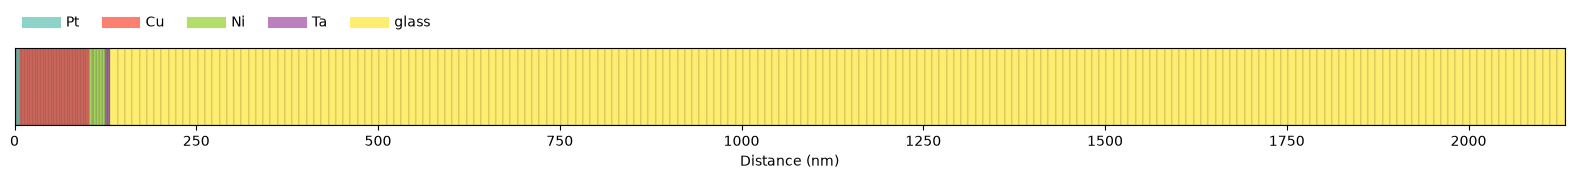

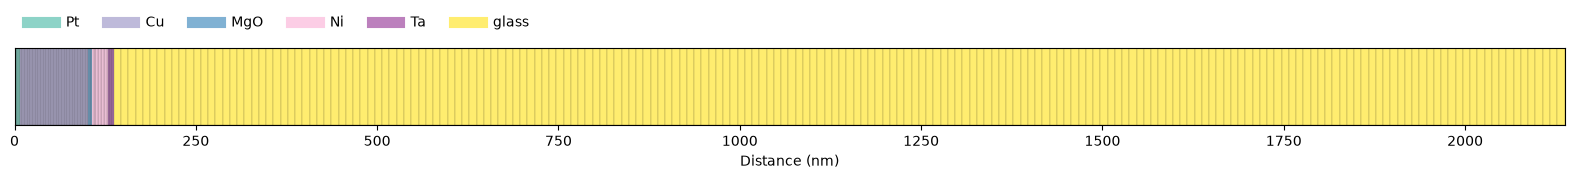

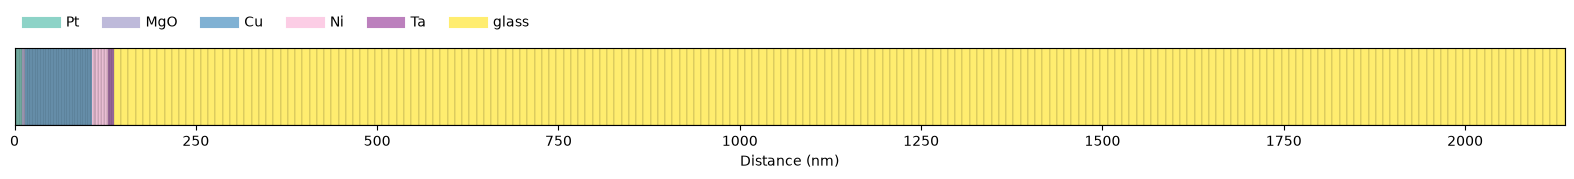

In [8]:
S_1.visualize()
S_2.visualize()
S_3.visualize()

## Initialize Heat and the Excitation

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

As in the experiment, the samples are excited from the Pt side by a 100 fs pump pulse at 800 nm under normal incidence with an incidence fluence of 7.5 mJ/cm².
Here, the 2TM is solved for all three samples.

In [9]:
# temporal grid
delays = np.r_[-20:600:0.5] * u.ps

res_temps = {}
for name, S in structures.items():
    h = ud.Heat(S, True)
    h.save_data = False
    h.disp_messages = False
    h.heat_diffusion = True
    h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
    h.excitation = {
        "fluence": [7.5] * u.mJ / u.cm**2,
        "delay_pump": [0] * u.ps,
        "pulse_width": [0.1] * u.ps,
        "multilayer_absorption": True,
        "wavelength": 800 * u.nm,
        "theta": 90 * u.deg,
    }
    res_temps[name] = h.get_temp_map(delays, 300 * u.K)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

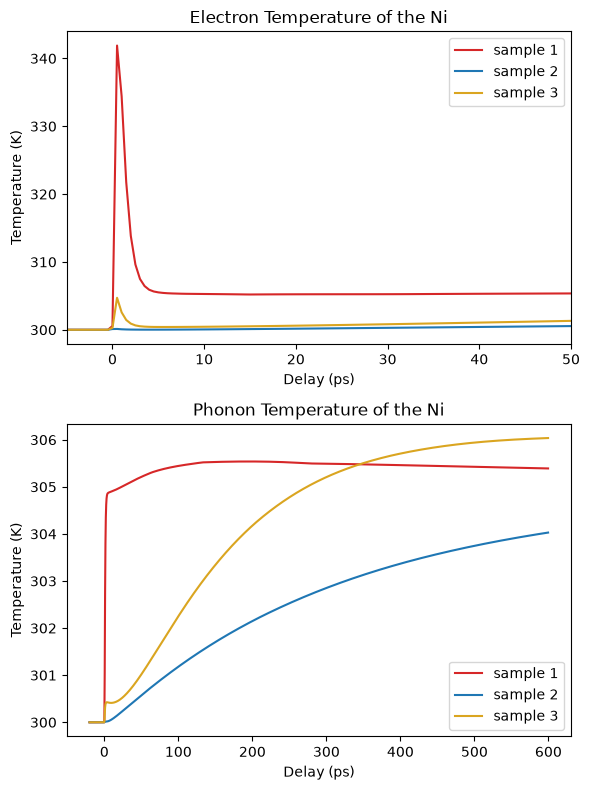

In [10]:
plt.figure(figsize=[6, 8])
for name, S in structures.items():
    select_Ni = S.positions_per_unique_layer["Ni"]
    plt.subplot(2, 1, 1)
    plt.plot(
        res_temps[name].quantity("delays", "ps"),
        np.mean(res_temps[name].temp_map[:, select_Ni, 0], axis=1),
        color=colors[name],
        label=name,
    )
    plt.subplot(2, 1, 2)
    plt.plot(
        res_temps[name].quantity("delays", "ps"),
        np.mean(res_temps[name].temp_map[:, select_Ni, 1], axis=1),
        color=colors[name],
        label=name,
    )

plt.subplot(2, 1, 1)
plt.xlim(-5, 50)
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Electron Temperature of the Ni")

plt.subplot(2, 1, 2)
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Phonon Temperature of the Ni")

plt.tight_layout()
plt.show()

Without MgO interlayer, the hot electrons transport the energy through the Cu into the Ni within a picosecond, where the strong electron-phonon coupling heats the phonons.
The MgO interlayer in front of the Ni (sample 2) or the Cu (sample 3) blocks this electronic heat transport, so that the Ni is only slowly heated by the phonons.

## Strain

Refer to the [strain pulses example](#example_strain_pulses) for more details.

The {py:class}`PhononNum <udkm1Dsim.simulations.phonons.PhononNum>` class calculates the strain of the heterostructures from the `temp_map` and its changes `delta_temp_map` of the heat simulations.
The strain is the superposition of the quasi-static expansion of the heated layers and of the strain pulses launched at their interfaces.
The 2 µm thick glass substrate ensures that the strain pulses reflected at its bottom do not return within the delay range.
For the LLG, the average strain $\eta_\mathrm{Ni}$ of the Ni layer is required.

:::{note}
The strain $\eta_\mathrm{Ni}$ in Fig. 3(e) of the paper was measured at a higher fluence of 13.2 mJ/cm² for the samples 1 and 2 and at the same fluence of 7.5 mJ/cm² for sample 3.
Hence, only the shape of the simulated strain can be compared for the samples 1 and 2.
:::

In [11]:
res_strains = {}
for name, S in structures.items():
    p = ud.PhononNum(S, True)
    p.save_data = False
    p.disp_messages = False
    res_strains[name] = p.get_strain_map(delays, res_temps[name])

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

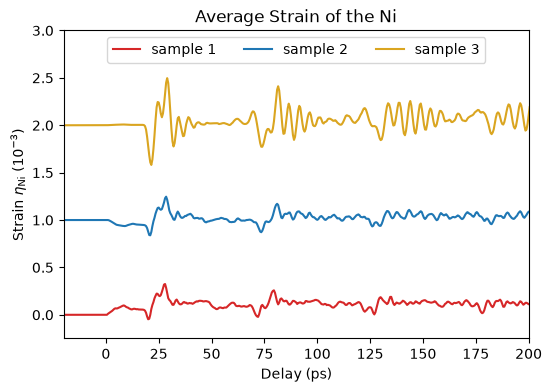

In [12]:
plt.figure(figsize=[6, 4])
for i, (name, S) in enumerate(structures.items()):
    select_Ni = S.positions_per_unique_layer["Ni"]
    eta_Ni = np.mean(res_strains[name].strain_map[:, select_Ni], axis=1)
    # offset for clarity
    plt.plot(
        res_strains[name].quantity("delays", "ps"),
        1e3 * eta_Ni + i,
        color=colors[name],
        label=name,
    )
plt.xlim(-20, 200)
plt.ylim(-0.25, 3)
plt.xlabel("Delay (ps)")
plt.ylabel(r"Strain $\eta_\mathrm{Ni}$ ($10^{-3}$)")
plt.legend(loc="upper center", ncol=3)
plt.title("Average Strain of the Ni")
plt.show()

In sample 1, the Ni is heated by the hot electrons and starts to expand right after the excitation.
In sample 2, the Ni is first compressed by the expansion of the rapidly heated Cu and expands only slowly as it is heated by the phonons.
In sample 3, the Ni remains unstrained until the strain pulse launched in the Pt arrives after about 20 ps.
Afterwards, the strain pulses echo through the heterostructures and periodically strain the Ni.

## Landau-Lifshitz-Gilbert Simulations

The {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order to overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can be enabled using the boolean switch `progress_bar`.

The `ode_options` are handed to `scipy.integrate.solve_ivp`.
Its default `LSODA` method switches automatically between a stiff and a non-stiff integrator, which is required e.g. for the [inertial LLG](#example_iLLG) and the [LLB](#example_LLB).
The LLG of the Ni layer is not stiff, so that the explicit `RK23` method is faster here.

In [13]:
llg = ud.LLG(S_1, True)

llg.save_data = False
llg.disp_messages = True
llg.progress_bar = False
llg.ode_options["method"] = "RK23"

llg

Landau-Lifshitz-Gilbert Magnetization Dynamics simulation properties:

========================  =======
               parameter  value
========================  =======
            force recalc  True
         cache directory  ./
        display messages  True
               save data  False
            progress bar  False
  temperature sub-system  0
magnetization sub-system
========================  =======

This is the current structure for the simulations:

Structure properties:

Name   : sample 1
Thickness : 2132 nm
----
7 times Platinum: 7 nm
95 times Copper: 95 nm
11 times Nickel: 22 nm
8 times Tantalum: 8 nm
200 times Glass: 2000 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Glass: 10 nm

### Precession at a Constant Amplitude

In order to run the LLG simulation, an initial magnetization `init_magnetization` as well as an external magnetic field `B_ext` can be provided.
Both are given in cartesian coordinates $[x, y, z]$, the external field in tesla or as quantity.
As the `magnetization` of the layers, the initial magnetization can also be given in polar coordinates as dict `{"r": ..., "phi": ..., "gamma": ...}` or as `VectorParameter`, with the angle $\phi$ from the $z$-axis and $\gamma$ in the $xy$-plane from the $x$-axis as in the [sketch of the coordinate system](#coordinate_system), see {py:meth}`parse_initial_magnetization <udkm1Dsim.simulations.magnetization.Magnetization.parse_initial_magnetization>`.
It is given either as single vector for all layers or as one vector per layer.
Without a `temp_map` or `mag_amplitude_map`, the amplitude of the LLG is the one of `init_magnetization`.

As in the experiment, the external field of 390 mT is applied at an angle $\xi$ from the film normal, here $\xi = 47°$.
The magnetization starts along $x$ in the film plane, with the amplitude of 300 K.

In [14]:
B_0 = 390 * u.mT  # strength of the external field
xi = np.radians(47)
B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])
init_mag = m_300 * np.array([1, 0, 0])  # along x
delays_free = np.r_[0:1000:0.5] * u.ps

res_mag = llg.get_magnetization_map(delays_free, init_magnetization=init_mag, B_ext=B_ext)

Calculating _magnetization_map_ ...
Elapsed time for _LLG_: 1.240926 s
Elapsed time for _magnetization_map_: 1.246443 s


:::{note}
The resulting `magnetization_map` is returned in **cartesian coordinates** $[m_x, m_y, m_z]$ as the `magnetization` of the layers.
With `polar=True`, it is returned in polar coordinates $[r, \phi, \gamma]$ with the angles in radians, as shown below.
Both are calculated from the same cached result.
Alternatively, the helpers {py:func}`convert_cartesian_to_polar <udkm1Dsim.helpers.convert_cartesian_to_polar>` and {py:func}`convert_polar_to_cartesian <udkm1Dsim.helpers.convert_polar_to_cartesian>` of the {py:mod}`helpers <udkm1Dsim.helpers>` module convert between both.
:::

:::{versionchanged} 2.6.1
The `magnetization_map` is returned in cartesian instead of polar coordinates by default.
Use `polar=True` for the former polar coordinates.
:::

Calculating _magnetization_map_ ...
Elapsed time for _LLG_: 1.272571 s
Elapsed time for _magnetization_map_: 1.276943 s


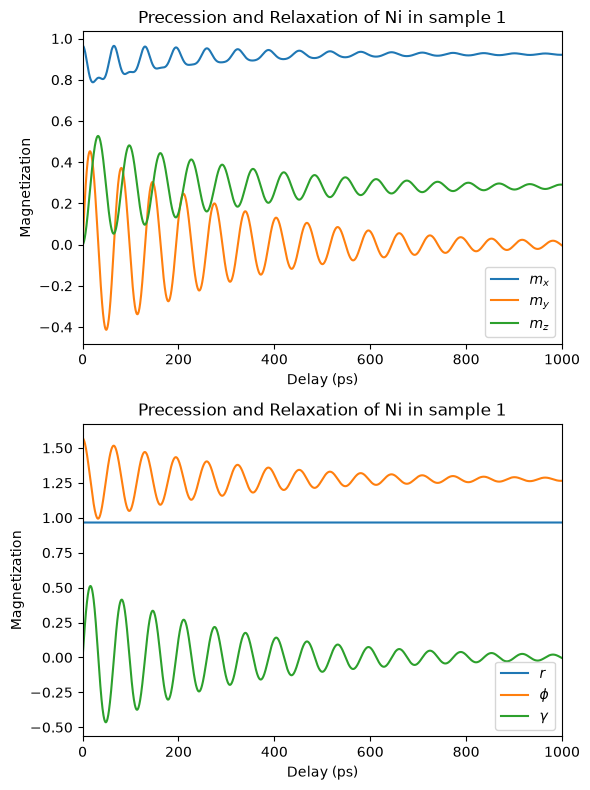

In [15]:
res_mag_polar = llg.get_magnetization_map(
    delays_free, init_magnetization=init_mag, B_ext=B_ext, polar=True
)
select_Ni = S_1.positions_per_unique_layer["Ni"]
m_xyz = np.mean(res_mag.magnetization_map[:, select_Ni, :], axis=1)
m_polar = np.mean(res_mag_polar.magnetization_map[:, select_Ni, :], axis=1)

plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(res_mag.quantity("delays", "ps"), m_xyz[:, 0], label="$m_x$")
plt.plot(res_mag.quantity("delays", "ps"), m_xyz[:, 1], label="$m_y$")
plt.plot(res_mag.quantity("delays", "ps"), m_xyz[:, 2], label="$m_z$")
plt.xlim(0, 1000)
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.legend()
plt.title("Precession and Relaxation of Ni in sample 1")

plt.subplot(2, 1, 2)
plt.plot(res_mag.quantity("delays", "ps"), m_polar[:, 0], label="$r$")
plt.plot(res_mag.quantity("delays", "ps"), m_polar[:, 1], label=r"$\phi$")
plt.plot(res_mag.quantity("delays", "ps"), m_polar[:, 2], label=r"$\gamma$")
plt.xlim(0, 1000)
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.legend()
plt.title("Precession and Relaxation of Ni in sample 1")

plt.tight_layout()
plt.show()

The magnetization precesses around the effective field and relaxes towards its equilibrium.
The frequency of small precessions around the equilibrium is given by the Smit-Beljers formula, Eq. (7) of {cite:t}`smit1955`, from the second derivatives of the energy, which is the generalization of the Kittel formula {cite:p}`kittel1948`, see also {cite:t}`baselgia1988`.
Here, it is written with the energy per magnetic moment, the mixed derivative $F_{\theta\varphi} = 0$ by symmetry, and the factor $1/(1+\alpha^2)$ of the Landau-Lifshitz form of the LLG.

:::{note}
Only in this section, the common notation of the Smit-Beljers formula is used: $\theta$ is the polar angle of the magnetization from the $z$-axis, i.e. the film normal, and $\varphi$ its azimuthal angle in the $xy$-plane from the $x$-axis.
They correspond to the angles $\phi$ and $\gamma$ of the `magnetization_map`, while $\gamma$ denotes the gyromagnetic ratio here.
:::

As the field, the magnetization lies in the $xz$-plane ($\varphi = 0$) and its energy per magnetic moment reads

\begin{align*}
F(\theta) = -B_\mathrm{ext}\left(\sin\xi \sin\theta + \cos\xi \cos\theta\right)
+ \frac{\mu_0 M_s m}{2} \cos^2\theta
\end{align*}

and its second derivatives at the equilibrium $F_{\theta\theta} = B_\mathrm{ext}\cos(\theta - \xi) - \mu_0 M_s m \cos 2\theta$ and $F_{\varphi\varphi} = B_\mathrm{ext}\sin\xi\sin\theta$ give the frequency

\begin{align*}
f = \frac{|\gamma|}{2\pi(1+\alpha^2)}\frac{\sqrt{F_{\theta\theta} F_{\varphi\varphi}}}{\sin\theta}.
\end{align*}

Since the field is below the saturation field of 620 mT, the magnetization is tilted between the field and the film plane, its easy plane.

In [16]:
# here gamma is the gyromagnetic ratio and not the azimuthal angle of the magnetization_map
gamma = abs(layer_Ni.gyromagnetic_ratio.to("rad/(s*T)").magnitude)
alpha = layer_Ni.gilbert_damping.magnitude
# demagnetizing field mu_0 M_s m at 300 K and the external field in tesla
B_d = (u.mu_0 * M_s_300).m_as("T")
B = B_0.m_as("T")
# grid of the polar angle theta of the magnetization from the film normal z,
# which is the angle phi of the magnetization_map
theta = np.linspace(0, np.pi, 100001)

# angles xi of the external field from the film normal z
xi_theory = np.radians(np.r_[1:90:1])
theta_eq = np.zeros(len(xi_theory))
f_smit_beljers = np.zeros(len(xi_theory))
for i, xi_i in enumerate(xi_theory):
    # energy per magnetic moment (T) of the magnetization in the xz-plane (phi = 0)
    F = -B * (np.sin(xi_i) * np.sin(theta) + np.cos(xi_i) * np.cos(theta))
    F += B_d / 2 * np.cos(theta) ** 2
    # the equilibrium theta_0 is the minimum of the energy, which lies between the
    # field direction (theta = xi) and the film plane (theta = 90°)
    theta_0 = theta[np.argmin(F)]
    # second derivatives of the energy with respect to theta and phi at theta_0
    F_tt = B * np.cos(theta_0 - xi_i) - B_d * np.cos(2 * theta_0)
    F_pp = B * np.sin(xi_i) * np.sin(theta_0)
    theta_eq[i] = theta_0
    f_smit_beljers[i] = (
        gamma / (2 * np.pi * (1 + alpha**2)) * np.sqrt(F_tt * F_pp) / np.sin(theta_0)
    )

# the field angle xi = 47° of the simulation above
i_47 = np.argmin(np.abs(xi_theory - xi))
print(f"equilibrium at 47°: {np.degrees(theta_eq[i_47]):.1f}° from the film normal")
print(f"Smit-Beljers frequency at 47°: {f_smit_beljers[i_47] * 1e-9:.2f} GHz")

# spectrum of the simulated precession
t = res_mag.quantity("delays", "s").magnitude
freqs = np.fft.rfftfreq(8 * len(t), t[1] - t[0])
spectrum = np.abs(
    np.fft.rfft((m_xyz[:, 1] - np.mean(m_xyz[:, 1])) * np.hanning(len(t)), 8 * len(t))
)
print(f"simulated frequency: {freqs[np.argmax(spectrum)] * 1e-9:.2f} GHz")

equilibrium at 47°: 73.1° from the film normal
Smit-Beljers frequency at 47°: 15.60 GHz
simulated frequency: 15.50 GHz


The simulated precession is slightly slower than the Smit-Beljers frequency, as it starts with a large angle from the equilibrium, while the formula holds for small precessions.

### Equilibrium Magnetization

Before an excitation, the magnetization typically rests in its equilibrium of the external field, the anisotropy, the exchange, and the strain.
Instead of simulating the precession for a long time until it has relaxed, {py:meth}`get_equilibrium_magnetization <udkm1Dsim.simulations.magnetization.Magnetization.get_equilibrium_magnetization>` relaxes the directions of the initial magnetization by an overdamped flow without precession into the nearest equilibrium.
It returns the magnetization of all layers and sublattices $L \times P \times 3$ in cartesian coordinates, or in polar coordinates for `polar=True`, as the `magnetization_map`.
The cartesian result can be used directly as `init_magnetization`.
The same is done by the option `equilibrate=True` of `get_magnetization_map` for the inputs at the first delay.

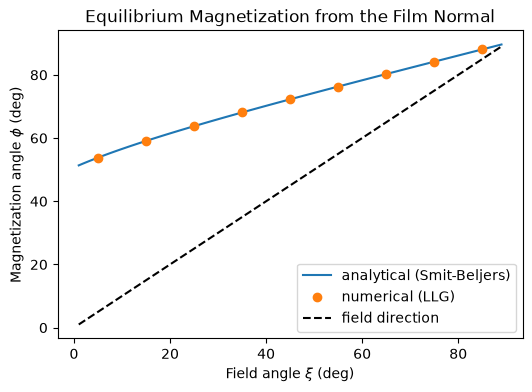

In [17]:
llg.disp_messages = False  # no messages for the scan
xi_scan = np.radians(np.r_[5:90:10])
phi_eq = np.zeros(len(xi_scan))
for i, xi_i in enumerate(xi_scan):
    B_ext_i = B_0 * np.array([np.sin(xi_i), 0, np.cos(xi_i)])
    res_equilibrium = llg.get_equilibrium_magnetization(
        B_ext=B_ext_i, init_magnetization=init_mag, polar=True
    )
    phi_eq[i] = res_equilibrium.equilibrium_magnetization[select_Ni[0], 0, 1]

plt.figure(figsize=[6, 4])
plt.plot(np.degrees(xi_theory), np.degrees(theta_eq), label="analytical (Smit-Beljers)")
plt.plot(np.degrees(xi_scan), np.degrees(phi_eq), "o", label="numerical (LLG)")
plt.plot(np.degrees(xi_theory), np.degrees(xi_theory), "k--", label="field direction")
plt.xlabel(r"Field angle $\xi$ (deg)")
plt.ylabel(r"Magnetization angle $\phi$ (deg)")
plt.legend()
plt.title("Equilibrium Magnetization from the Film Normal")
plt.show()

The numerical equilibrium of the LLG, i.e. of all Ni layers coupled by the exchange, agrees with the analytical minimum of the energy of the Smit-Beljers formula.
The shape anisotropy pulls the magnetization towards the film plane, so that it always lies between the field direction and the film plane.
Since the external field of 390 mT is below the saturation field of $\mu_0 M_s = 620$ mT, the magnetization remains tilted by $\cos\phi = B_\mathrm{ext} / (\mu_0 M_s)$, i.e. by about 51° from the film normal, even for a field along the film normal.
For a field in the film plane, the magnetization is parallel to the field.

### Magnetization Amplitude from the Temperature

With a given `temp_map`, the magnetization amplitude of the LLG becomes a time-dependent mean-field magnetization $m(t) = m_\mathrm{eq}(T(t))$.
For a `temp_map` of multiple subsystems, the relevant one can be selected by the `temp_sub_system` property, see {py:meth}`get_mean_field_mag_map <udkm1Dsim.simulations.magnetization.Magnetization.get_mean_field_mag_map>`.
Following the paper, which uses the static magnetization of the phonon temperature, the phonons are seleted here as well.

:::{note}
This *adiabatic limit* assumes that the magnetization follows the temperature instantaneously, otherwise the [LLB](#example_LLB) is required.
:::

As the shape anisotropy scales with $m^{\beta-1}$, the drop of the amplitude reduces the demagnetizing field and tilts the effective field towards the film normal, which drives a precession {cite:p}`vankampen2002`.
The magnetization starts in the equilibrium of the first delay, and the same `delays` of the heat and strain simulations can be reused.
For sample 1 at a field angle of $\xi = 5°$ the demagnetization of the Ni drives the precession most efficiently.

In [18]:
llg.temp_sub_system = 1  # the phonons
xi = np.radians(5)
B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])

res_mag_temp = llg.get_magnetization_map(
    delays,
    temp_map=res_temps["sample 1"],
    init_magnetization=init_mag,
    B_ext=B_ext,
    equilibrate=True,
)

Instead of the mean field, the amplitude can also be given directly as `mag_amplitude_map` of the dimension $M \times L$ for all layers, e.g. from a phenomenological model, a measurement, or the microscopic three-temperature model of the [M3TM example](#example_m3tm).
Here, the mean-field magnetization of the phonon temperature is given directly, which reproduces the simulation above.

In [19]:
# phonon temperature of the temp_sub_system 1 as input
res_mf = llg.get_mean_field_mag_map(res_temps["sample 1"])

res_mag_amp = llg.get_magnetization_map(
    delays,
    mag_amplitude_map=res_mf,
    init_magnetization=init_mag,
    B_ext=B_ext,
    equilibrate=True,
)
deviation = np.max(np.abs(res_mag_amp.magnetization_map - res_mag_temp.magnetization_map))
print(f"largest deviation: {deviation:.1e}")

largest deviation: 0.0e+00


### Strain and Magnetoelastic Coupling

The out-of-plane strain $\eta$ enters the LLG via the `strain_map` as magnetoelastic field $\mathbf{B}_\mathrm{me} = -\frac{2 B_1 \eta}{M_s} m^{\beta-2} m_z \hat{\mathbf{z}}$, see {py:func}`magnetoelastic_field <udkm1Dsim.simulations.solvers.magnetization_scipy.magnetoelastic_field>`, i.e. as additional anisotropy along $z$, which drives magnetoacoustic precession {cite:p}`kim2012`.
Here, the change of the out-of-plane magnetization $\Delta m_z$ of the Ni due to the demagnetization alone, due to the strain alone, i.e. at a constant amplitude, and due to both together are compared.

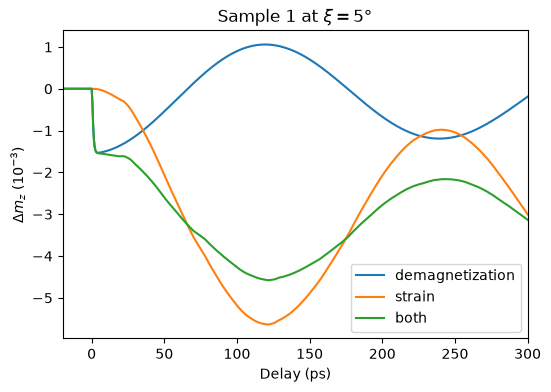

In [20]:
res_mag_strain = llg.get_magnetization_map(
    delays,
    strain_map=res_strains["sample 1"],
    init_magnetization=init_mag,
    B_ext=B_ext,
    equilibrate=True,
)
res_mag_both = llg.get_magnetization_map(
    delays,
    temp_map=res_temps["sample 1"],
    strain_map=res_strains["sample 1"],
    init_magnetization=init_mag,
    B_ext=B_ext,
    equilibrate=True,
)

plt.figure(figsize=[6, 4])
for label, result in [
    ("demagnetization", res_mag_temp),
    ("strain", res_mag_strain),
    ("both", res_mag_both),
]:
    m_z = np.mean(result.magnetization_map[:, select_Ni, 2], axis=1)
    plt.plot(result.quantity("delays", "ps"), 1e3 * (m_z - m_z[0]), label=label)

plt.xlim(-20, 300)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$\Delta m_z$ ($10^{-3}$)")
plt.legend()
plt.title(r"Sample 1 at $\xi = 5°$")
plt.show()

The demagnetization reduces $m_z$ within picoseconds and tilts the effective field towards the film normal, whereas the expansion of the Ni tilts it towards the film plane.
Both drive the precession with opposite phase, and the quasi-static strain dominates, as observed in the paper.

## Heterostructure-Dependent Precession

Now the three heterostructures at the field angles of Fig. 2(c) and (d) of the paper, $\xi = 5°$ and $\xi = 47°$, are compared.
Every structure is assigned to its own {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>` object, which is stored in a `dict` for convenience.

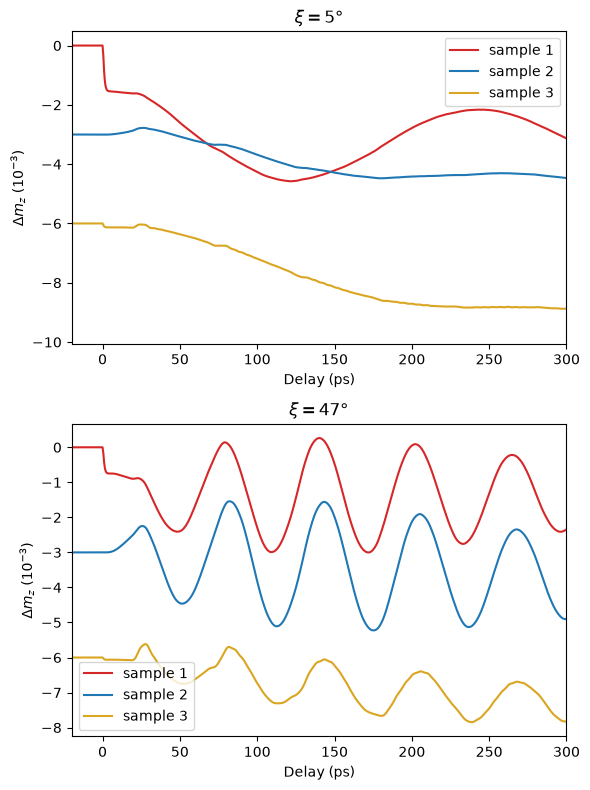

In [21]:
llgs = {}
for name, S in structures.items():
    llgs[name] = ud.LLG(S, True)
    llgs[name].save_data = False
    llgs[name].disp_messages = False
    llgs[name].progress_bar = False
    llgs[name].ode_options["method"] = "RK23"
    llgs[name].temp_sub_system = 1

plt.figure(figsize=[6, 8])
for k, xi_deg in enumerate([5, 47]):
    xi = np.radians(xi_deg)
    B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])
    plt.subplot(2, 1, k + 1)
    for i, (name, S) in enumerate(structures.items()):
        select_Ni = S.positions_per_unique_layer["Ni"]
        res_mag = llgs[name].get_magnetization_map(
            delays,
            temp_map=res_temps[name],
            strain_map=res_strains[name],
            init_magnetization=init_mag,
            B_ext=B_ext,
            equilibrate=True,
        )
        m_z = np.mean(res_mag.magnetization_map[:, select_Ni, 2], axis=1)
        # offset for clarity
        plt.plot(
            res_mag.quantity("delays", "ps"),
            1e3 * (m_z - m_z[0]) - 3 * i,
            color=colors[name],
            label=name,
        )
    plt.xlim(-20, 300)
    plt.xlabel("Delay (ps)")
    plt.ylabel(r"$\Delta m_z$ ($10^{-3}$)")
    plt.legend()
    plt.title(rf"$\xi = {xi_deg}°$")

plt.tight_layout()
plt.show()

At $\xi = 5°$ only the rapid heating of the Ni via hot electrons in sample 1 drives a pronounced precession.
At $\xi = 47°$ all samples precess, driven by the strain pulses echoing through the heterostructure, and the precession of sample 3 starts only when the strain pulse of the Pt arrives in the Ni.

### Magneto-Acoustic Resonance

Finally, the angle $\xi$ of the external field from the film normal to the film plane as in Fig. 2(a) and (b) of the paper is scanned and the frequency and the amplitude of the precession from the Fourier transform of $\Delta m_z$, after subtracting its slow background, is extracted.

In [22]:
xi_scan = np.r_[0:91:5]
t = res_temps["sample 1"].quantity("delays", "s").magnitude  # required for the FFT
after = t >= 0
freqs = np.fft.rfftfreq(8 * np.sum(after), t[1] - t[0])
amplitudes = {}
frequencies = {}
delta_m_z_maps = {}
for name, S in structures.items():
    select_Ni = S.positions_per_unique_layer["Ni"]
    amplitudes[name] = np.zeros(len(xi_scan))
    frequencies[name] = np.zeros(len(xi_scan))
    delta_m_z_maps[name] = np.zeros([len(xi_scan), len(t)])
    for i, xi_deg in enumerate(xi_scan):
        xi = np.radians(xi_deg)
        B_ext = B_0 * np.array([np.sin(xi), 0, np.cos(xi)])
        res_mag = llgs[name].get_magnetization_map(
            delays,
            temp_map=res_temps[name],
            strain_map=res_strains[name],
            init_magnetization=init_mag,
            B_ext=B_ext,
            equilibrate=True,
        )
        m_z = np.mean(res_mag.magnetization_map[:, select_Ni, 2], axis=1)
        delta_m_z_maps[name][i, :] = m_z - m_z[0]
        delta_m_z = m_z[after] - m_z[0]
        # subtract the slow background
        delta_m_z -= np.polyval(np.polyfit(t[after], delta_m_z, 2), t[after])
        spectrum = np.abs(np.fft.rfft(delta_m_z * np.hanning(len(delta_m_z)), 8 * len(delta_m_z)))
        spectrum[freqs < 3e9] = 0
        amplitudes[name][i] = spectrum.max()
        frequencies[name][i] = freqs[np.argmax(spectrum)]

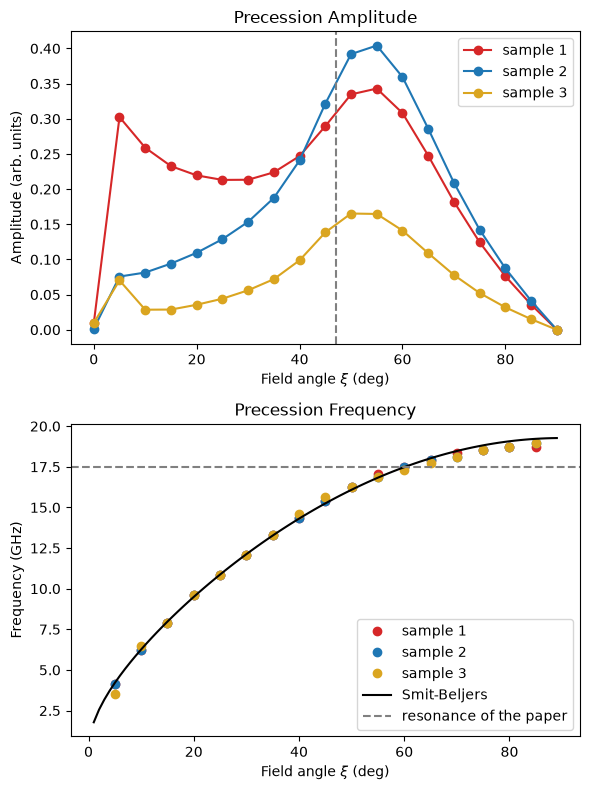

In [23]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for name in structures.keys():
    plt.plot(xi_scan, amplitudes[name], "o-", color=colors[name], label=name)
plt.xlabel(r"Field angle $\xi$ (deg)")
plt.ylabel("Amplitude (arb. units)")
plt.axvline(47, color="gray", ls="--")
plt.legend()
plt.title("Precession Amplitude")

plt.subplot(2, 1, 2)
for name in structures.keys():
    plt.plot(xi_scan[1:-1], frequencies[name][1:-1] * 1e-9, "o", color=colors[name], label=name)
plt.plot(np.degrees(xi_theory), f_smit_beljers * 1e-9, "k-", label="Smit-Beljers")
plt.axhline(17.5, color="gray", ls="--", label="resonance of the paper")
plt.xlabel(r"Field angle $\xi$ (deg)")
plt.ylabel("Frequency (GHz)")
plt.legend()
plt.title("Precession Frequency")

plt.tight_layout()
plt.show()

The frequency of all samples follows the Smit-Beljers formula and increases as the field is tilted towards the film plane.
The amplitude of sample 1 is largest for an out-of-plane field, where the rapid demagnetization and expansion of the Ni drive the precession.
For all samples, the amplitude is resonantly enhanced at a precession frequency of about 17 GHz, when the strain pulses echoing through the heterostructure periodically drive the precession.
This magneto-acoustic resonance is strongest for sample 2, whose spatially extended strain pulse launched by the Cu matches the phase of the precession, and much weaker for sample 3, whose narrow bipolar pulse launched by the Pt nearly cancels within a precession period.

These are the findings of {cite:t}`jarecki2024`, who observe the resonance at 17.5 GHz.
The strain echoes in the simulation have the same frequency, but the stated parameters of the paper give a precession frequency of only 15.6 GHz at 47°, which reaches 17.5 GHz at about 60°.
Hence, the resonance appears at a larger field angle than in the paper, whose measured and modelled frequencies are slightly larger.

### Precession for a Full Rotation of the Field

Fig. 1(c) of the paper shows $\Delta m_z$ of sample 1 for a full rotation of the external field in the $xz$-plane.
For a field exactly along the film normal or in the film plane, the change of the effective field is parallel to the precession axis, so that $m_z$ does not oscillate.

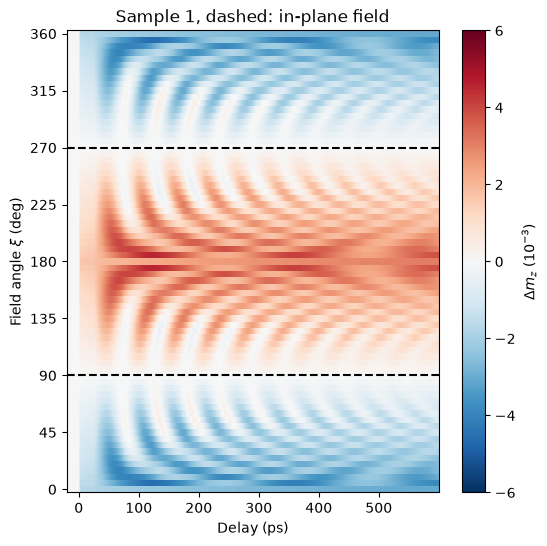

In [24]:
# Due to the symmetry of the shape anisotropy and the magnetoelastic field, the
# scan from 0° to 90° above gives the full rotation: xi -> 180° - xi and
# xi -> 180° + xi reverse m_z, while xi -> 360° - xi keeps it.
delta_m_z = delta_m_z_maps["sample 1"]
xi_full = np.r_[xi_scan, 180 - xi_scan[::-1][1:], 180 + xi_scan[1:], 360 - xi_scan[::-1][1:]]
delta_m_z_full = np.r_[delta_m_z, -delta_m_z[::-1][1:], -delta_m_z[1:], delta_m_z[::-1][1:]]

plt.figure(figsize=[6, 6])
plt.pcolormesh(
    res_temps["sample 1"].quantity("delays", "ps"),
    xi_full,
    1e3 * delta_m_z_full,
    shading="auto",
    cmap="RdBu_r",
    vmin=-6,
    vmax=6,
)
plt.colorbar(label=r"$\Delta m_z$ ($10^{-3}$)")
plt.axhline(90, color="k", ls="--")
plt.axhline(270, color="k", ls="--")
plt.yticks(np.r_[0:361:45])
plt.xlabel("Delay (ps)")
plt.ylabel(r"Field angle $\xi$ (deg)")
plt.title("Sample 1, dashed: in-plane field")
plt.show()